In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
SEASON = 2026
TEAM_GAMES = "../data/processed/team_games.csv"
TEAM_SEASONS = "../data/processed/team_seasons.csv"
TEAMS = "../data/processed/teams.csv"


# Exploratory Data Analysis - Marvin G

### Guiding Questions

- What did the distribution of points scored last season look like?
- What about the margin between winner and opponents?
- Which teams scored the most and least last season? 
- How often did the higher ranked opponent beat the lower ranked opponent last season? 
- What was the distribution of the margin for those matches?
- Was it any different from the overall?

Text(0.5, 1.0, '2025-2026 NCAA Basketball Margin Distribution')

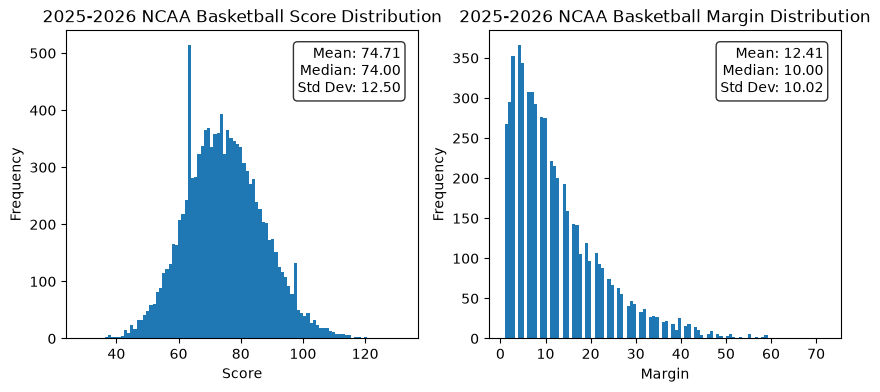

In [60]:
games_df = pd.read_csv(TEAM_GAMES, low_memory=False)
teams_df = pd.read_csv(TEAMS)
d1_ids = set(teams_df.loc[(teams_df["season"] == SEASON) & teams_df["is_d1"], "team_id"])

# 2026 Season completed games between two D1 teams
season_2026_games_df = games_df[
    (games_df["season"] == SEASON)
    & games_df["completed"]
    & games_df["team_id"].isin(d1_ids)
    & games_df["opponent_id"].isin(d1_ids)
]

# 2026 Season scores
season_2026_points_scored = season_2026_games_df["team_score"]
season_2026_points_scored.to_numpy()

# 2026 Season margin
season_2026_points_margin = season_2026_games_df[season_2026_games_df["margin"] > 0]
season_2026_points_margin = season_2026_points_margin["margin"]
season_2026_points_margin.to_numpy()

# 2026 Season summary statistics for points scored
points_scored_mean = season_2026_points_scored.mean()
points_scored_median = season_2026_points_scored.median()
points_scored_std = season_2026_points_scored.std()

# 2026 Season summary statistics for the margin 
margin_mean = season_2026_points_margin.mean()
margin_median = season_2026_points_margin.median()
margin_std = season_2026_points_margin.std()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Points distribution plot
ax1.hist(season_2026_points_scored, bins=100)
ax1.set_xlabel("Score")
ax1.set_ylabel("Frequency")

stats_text1 = (
    f"Mean: {points_scored_mean:.2f}\n"
    f"Median: {points_scored_median:.2f}\n"
    f"Std Dev: {points_scored_std:.2f}"
)

ax1.text(
    0.95, 0.95,
    stats_text1,
    transform=ax1.transAxes,
    fontsize=10,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)
ax1.set_title("2025-2026 NCAA Basketball Score Distribution")

# Margin distribution plot
ax2.hist(season_2026_points_margin, bins=100)
ax2.set_xlabel("Margin")
ax2.set_ylabel("Frequency")

stats_text2 = (
    f"Mean: {margin_mean:.2f}\n"
    f"Median: {margin_median:.2f}\n"
    f"Std Dev: {margin_std:.2f}"
)

ax2.text(
    0.95, 0.95,
    stats_text2,
    transform=ax2.transAxes,
    fontsize=10,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

ax2.set_title("2025-2026 NCAA Basketball Margin Distribution")

In [66]:
season_2026_team_seasons_df = pd.read_csv(TEAM_SEASONS)
season_2026_team_seasons_df = season_2026_team_seasons_df[
    (season_2026_team_seasons_df["season"] == SEASON)
    & (season_2026_team_seasons_df["split"] == "Overall")
]
season_2026_team_seasons_df_sorted = season_2026_team_seasons_df.sort_values(by="ppg")
season_2026_most_points_teams = season_2026_team_seasons_df_sorted[-10:]
season_2026_least_points_teams = season_2026_team_seasons_df_sorted[:10]

season_2026_least_points_teams

,season,team_id,split,team,conference,games,wins,losses,ppg,opp_ppg,...,drtg_rank,pace_rank,efg_pct_rank,tov_pct_rank,orb_pct_rank,ft_rate_rank,opp_efg_pct_rank,opp_tov_pct_rank,opp_orb_pct_rank,opp_ft_rate_rank
200,2026,2169,Overall,Delaware State,MEAC,31,8,23,61.2,70.5,...,128,287,363,345,280,253,273,41,188,290
170,2026,2005,Overall,Air Force,Mountain West,32,3,29,61.5,79.9,...,358,241,310,361,361,178,356,301,251,241
150,2026,311,Overall,Maine,Am. East,32,8,24,62.5,68.4,...,115,327,246,324,364,101,158,39,331,156
188,2026,2099,Overall,Canisius,Metro,31,10,21,62.9,70.5,...,225,350,351,343,230,276,228,213,157,202
290,2026,2520,Overall,Rider,Metro,29,4,25,63.4,76.0,...,342,313,364,213,112,283,328,274,311,128
149,2026,309,Overall,Louisiana,Sun Belt,33,11,22,63.7,70.7,...,264,357,344,192,274,331,274,93,291,356
152,2026,315,Overall,Niagara,Metro,30,8,22,63.9,71.2,...,312,362,232,314,341,354,282,182,295,146
251,2026,2400,Overall,Mississippi Valley State,SWAC,33,3,30,64.2,83.0,...,357,109,356,360,325,215,345,142,350,362
246,2026,2379,Overall,Maryland Eastern Shore,MEAC,32,9,23,64.4,70.8,...,182,339,296,364,115,326,143,100,306,328
351,2026,2803,Overall,Bryant,Am. East,31,9,22,64.8,72.5,...,260,338,334,351,271,298,221,318,220,129


In [64]:
season_2026_most_points_teams

,season,team_id,split,team,conference,games,wins,losses,ppg,opp_ppg,...,drtg_rank,pace_rank,efg_pct_rank,tov_pct_rank,orb_pct_rank,ft_rate_rank,opp_efg_pct_rank,opp_tov_pct_rank,opp_orb_pct_rank,opp_ft_rate_rank
64,2026,139,Overall,Saint Louis,A-10,35,29,6,87.2,70.5,...,18,28,4,218,165,227,1,234,43,249
62,2026,130,Overall,Michigan,Big Ten,40,37,3,87.3,69.5,...,13,48,9,163,64,93,2,297,91,19
30,2026,58,Overall,South Florida,American,34,25,9,87.5,75.7,...,53,13,228,61,10,51,58,48,263,282
171,2026,2006,Overall,Akron,MAC,35,29,6,87.9,74.0,...,89,43,8,80,80,342,157,78,152,55
86,2026,172,Overall,Cornell,Ivy,28,15,13,88.5,83.4,...,335,30,5,146,177,327,339,261,159,216
32,2026,61,Overall,Georgia,SEC,33,22,11,89.4,79.8,...,176,11,76,36,58,123,165,89,346,76
90,2026,193,Overall,Miami (OH),MAC,34,32,2,89.6,75.5,...,95,42,2,33,329,71,132,132,97,47
222,2026,2272,Overall,High Point,Big South,36,31,5,89.7,71.2,...,23,35,22,3,116,36,107,6,175,193
3,2026,8,Overall,Arkansas,SEC,37,28,9,90.2,81.0,...,250,16,19,1,147,155,234,265,235,95
159,2026,333,Overall,Alabama,SEC,35,25,10,91.2,82.7,...,280,5,40,9,134,152,85,361,305,112


In [ ]:
# NCAA tournament games excluded: their rank column held seeds, not AP ranks
decided_df = season_2026_games_df[
    (season_2026_games_df["margin"] > 0)
    & (season_2026_games_df["season_type"] == "Regular Season")
]
winner_ranked = decided_df["rank"].notna()
loser_ranked = decided_df["opponent_rank"].notna()

both_ranked_df = decided_df[winner_ranked & loser_ranked]
both_ranked_upsets = (both_ranked_df["rank"] > both_ranked_df["opponent_rank"]).sum()

one_ranked_df = decided_df[winner_ranked ^ loser_ranked]
one_ranked_upsets = one_ranked_df["rank"].isna().sum()

upsets_df = pd.DataFrame(
    {
        "games": [len(both_ranked_df), len(one_ranked_df)],
        "upsets": [both_ranked_upsets, one_ranked_upsets],
    },
    index=["Ranked vs ranked", "Ranked vs unranked"],
)
upsets_df["favorite_wins"] = upsets_df["games"] - upsets_df["upsets"]
upsets_df["upset_rate"] = (upsets_df["upsets"] / upsets_df["games"]).round(3)
upsets_df